# What Happens to Drug Prices?

Every week the U.S. government publishes what pharmacies really paid for each
medicine. 
Collected 34 weeks, around a million records.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# All the real work lives in pharmacli/frame.py, so this notebook stays readable.
from pharmacli.frame import brand_generic, gini, load, weekly_change

plt.rcParams.update({"figure.figsize": (8, 3.4), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = load("../pharmacli.db")
print(f"We have {len(df):,} price records.")
print(f"They cover {df.ndc.nunique():,} different medicines over {df.as_of_date.nunique()} weeks.")
print(f"One row = one medicine, in one week, with the price paid that week.")

We have 1,028,250 price records.
They cover 32,509 different medicines over 34 weeks.
One row = one medicine, in one week, with the price paid that week.


---
## Question 1 — Do drug prices actually change?

You would think a price is a price. Let's check.

In [ ]:
# Compare each medicine's price to its price the week before.
ch = weekly_change(df).dropna(subset=["wow"])
same = (ch.wow == 0).mean()

print(f"We looked at {len(ch):,} chances for a price to change.")
print(f"The price stayed exactly the same {same*100:.0f} times out of 100.")
print(f"So a price changes about {(1-same)*100:.0f} times out of 100 weeks.")

### Most weeks, nothing happens. About 1 week in 5, the price moves.

Prices sit still for weeks, then jump

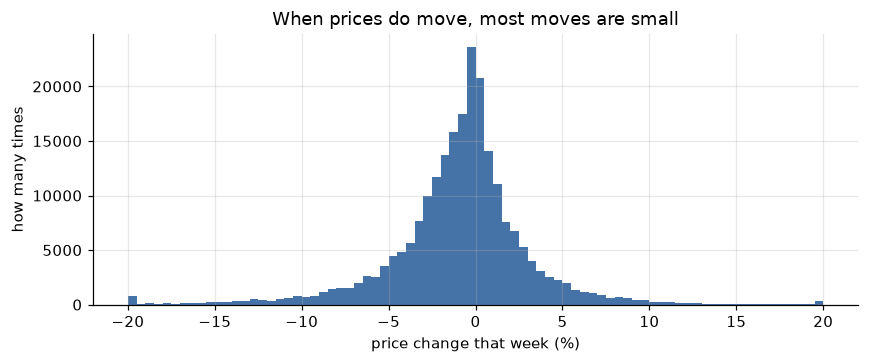

Half of all changes are smaller than 1.7%.


In [ ]:
# Show it: how big are the changes, when there IS one?
moved = ch[ch.wow != 0]
fig, ax = plt.subplots()
ax.hist(np.clip(moved.wow * 100, -20, 20), bins=80, color="#4573a7")
ax.set(xlabel="price change that week (%)", ylabel="how many times",
       title="When prices do move, most moves are small")
plt.tight_layout(); plt.show()
print(f"Half of all changes are smaller than {moved.wow.abs().median()*100:.1f}%.")

---
## Which changes more: cheap copies, or brand names?

In [ ]:
# "G" means generic
ch["is_generic"] = ch.rate_class == "G"
t = ch.groupby("is_generic").wow.agg(
    weeks="size",
    moved=lambda s: (s != 0).mean(),
    typical_move=lambda s: s[s != 0].abs().median())

for is_gen, r in t.iterrows():
    name = "Generics" if is_gen else "Brands  "
    print(f"{name}: price moves {r.moved*100:4.0f} weeks out of 100, "
          f"and a typical move is {r.typical_move*100:5.2f}%")

Brands  : price moves   14 weeks out of 100, and a typical move is  0.05%
Generics: price moves   24 weeks out of 100, and a typical move is  1.87%


### **Generics moves are ~37x bigger.**

Lots of companies make generics, so they fight on price. So a larger portion of price competitiveness is in generic brands not 

---
## Question 3 — How much more does a brand cost than its copy?

In [5]:
bg = brand_generic(df)                      # only rows that have both prices
true_brand = bg[bg.rate_class == "B"].ratio
authorized = bg[bg.rate_class == "B-ANDA"].ratio   # a brand sold as a generic

print(f"A real brand costs {true_brand.median():.1f} times its generic copy.")
print(f"An 'authorized generic' costs only {authorized.median():.1f} times.")
print()
print(f"Out of {len(true_brand):,} brand prices we compared,")
print(f"the most extreme 10% cost more than {true_brand.quantile(.9):.0f}x the generic.")

A real brand costs 13.6 times its generic copy.
An 'authorized generic' costs only 1.4 times.

Out of 33,327 brand prices we compared,
the most extreme 10% cost more than 202x the generic.


### A brand costs about 14x its generic copy. Sometimes 200x.
An "authorized generic" is the brand companies generic. It costs only about 1.4x.

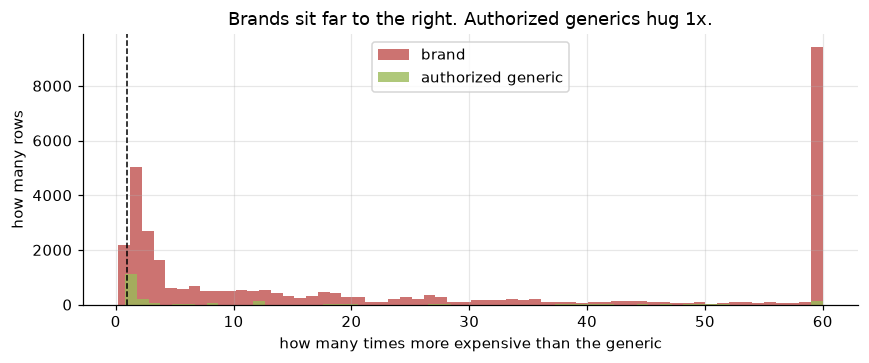

In [6]:
fig, ax = plt.subplots()
ax.hist(np.clip(true_brand, 0, 60), bins=60, color="#c0504d", alpha=.8, label="brand")
ax.hist(np.clip(authorized, 0, 60), bins=60, color="#9bbb59", alpha=.8, label="authorized generic")
ax.axvline(1, color="k", lw=1, ls="--")
ax.set(xlabel="how many times more expensive than the generic", ylabel="how many rows",
       title="Brands sit far to the right. Authorized generics hug 1x.")
ax.legend(); plt.tight_layout(); plt.show()

---
## Question 4 — Is the movement in a few drugs, or spread across many?


In [7]:
# Add up how much each medicine moved in total over the 34 weeks.
total = moved.groupby("ndc", observed=True).wow.apply(lambda s: s.abs().sum())
total = total[total > 0]
share_of_all = total.nlargest(len(total) // 10).sum() / total.sum()

print(f"{len(total)/df.ndc.nunique()*100:.0f} out of every 100 medicines moved at least once.")
print(f"The busiest 10% of them caused only {share_of_all*100:.0f}% of all the movement.")
print(f"Unevenness score: {gini(total):.2f}   (0 = perfectly even, 1 = one drug does everything)")

96 out of every 100 medicines moved at least once.
The busiest 10% of them caused only 30% of all the movement.
Unevenness score: 0.43   (0 = perfectly even, 1 = one drug does everything)


### Every drug moves

97 out of 100 medicines changed price at least once.

The busiest 10% caused only about 30% of the movement. 

---
## Question 5 — What surprised us?



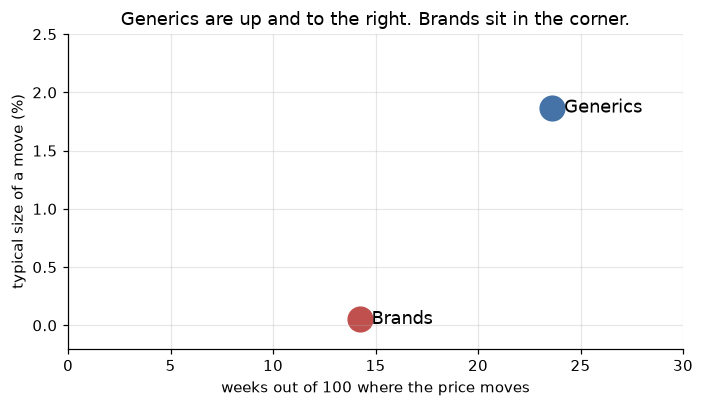

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for is_gen, r in t.iterrows():
    label = "Generics" if is_gen else "Brands"
    color = "#4573a7" if is_gen else "#c0504d"
    ax.scatter(r.moved * 100, r.typical_move * 100, s=260, color=color)
    ax.annotate(f"  {label}", (r.moved * 100, r.typical_move * 100), va="center", fontsize=12)
ax.set(xlabel="weeks out of 100 where the price moves",
       ylabel="typical size of a move (%)",
       title="Generics are up and to the right. Brands sit in the corner.",
       xlim=(0, 30), ylim=(-0.2, 2.5))
plt.tight_layout(); plt.show()

### Brands do not move, generics do

Brand prices are almost frozen. Generic prices are the restless ones.

One more thing we did not expect: the government reprices on a monthly
schedule.